# Fourier Transform IR Spectroscopy: Deconvolution and Peak Fitting, 2nd Derivative Method
## A CS319 Final Project by Rebecca Goodman
#### In this notebook you will find the necessary tools to take .dpt files of FTIR spectra data and work it up to identify secondary structures of proteins. Documented are the steps for installation of necessary packages, helpful resources for FTIR methods and peak identification, as well as an interactive peak fitter. Any lines of code bound by triple hashtags indicate code that can be manipulated for changing the final results. Please note that this program assumes you already subtracted any background/solvents, and that you named your replicates "Sample1_A.dpt", "Sample1_B.dpt", "Sample2_A.dpt" etc. If this is not the case, either rename your files accordingly or alter the code in the Data Formatting sections

### Imports
#### In the below cell are all the required module imports. Please note that some of these items must first be imported via the terminal using conda install commands. The lines to do this and the documentation is listed below:
##### For MatPlotLib: https://matplotlib.org/stable/install/index.html 
##### conda install matplotlib
##### For Numpy: https://numpy.org/install/
##### conda create -n my-env
##### conda activate my-env
##### conda install numpy
##### For SciPy: https://scipy.org/install/
##### conda install scipy

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import scipy

##### In the below cell is how you import your folder of data into the notebook and convert them into DataFrames. For sake of convenience, ensure the folder encasing the Notebook also contains the folder of data.

In [2]:
data_path = './Data/' ###Change 'Example' to whatever your file is named that contains your data###
all_data = os.listdir(data_path)
og_data = {}
for file in all_data:
    if not file.startswith("."):
        try:
            og_data[file]= pd.read_csv(os.path.join(data_path,file), sep="\t", names = ["Wavenumber","Abs_A"])
        except UnicodeDecodeError:
            print(file)
            break

### Data Formatting 
#### The below cells convert all the imported data into workable chunks
##### This cell changes the names of all folders to remove the .dpt and leaves just the identifying information. The new Dataframes are now in a dictionary "nice_data"

In [3]:
nice_data = {}
for file in og_data:
    nice_data[file[:-4]] = og_data[file]

##### This cell makes a new nested dictionary “avg_data” where each sample type is a key and the replicates can be stored as different data frames.

In [4]:
avg_data = {}
for file in nice_data:
    if file[-1] != "A":
        continue
    sample_type = file[:-2]
    if sample_type not in avg_data:
        avg_data[sample_type] = nice_data[file]

for file in avg_data:
    for entry in nice_data:
        if entry[:-2] == file:
            if entry[-1] == "B":
                avg_data[file]["Abs_"+entry[-1]] = nice_data[entry]["Abs_A"]
            elif entry[-1] == "C":
                avg_data[file]["Abs_"+entry[-1]] = nice_data[entry]["Abs_A"]
            elif entry[-1] == "D":
                avg_data[file]["Abs_"+entry[-1]] = nice_data[entry]["Abs_A"]
            elif entry[-1] == "E":
                avg_data[file]["Abs_"+entry[-1]] = nice_data[entry]["Abs_A"]
            elif entry[-1] == "F":
                avg_data[file]["Abs_"+entry[-1]] = nice_data[entry]["Abs_A"]
            elif entry[-1] == "G":
                avg_data[file]["Abs_"+entry[-1]] = nice_data[entry]["Abs_A"]
            ###Add more elif statments if you have more than A-G replicates###

##### Genrally for protein secondary structure, only the Amide I peak is analyzed. The below cell slices the dataframes to include only the Amide I (1700-1600) region

In [5]:
for file in avg_data:
    avg_data[file]["Wavenumber"] = avg_data[file]["Wavenumber"].astype(float)
    avg_data[file] = avg_data[file][avg_data[file]["Wavenumber"] <= 1700]
    avg_data[file] = avg_data[file][avg_data[file]["Wavenumber"] >= 1590]

##### Run the below cell if you wish to double check your files

In [6]:
for file in avg_data:
    print(file)
    for item in avg_data[file]:
        print("\t" + item)
print(avg_data)

8LOOP1
	Wavenumber
	Abs_A
	Abs_B
	Abs_C
	Abs_D
{'8LOOP1':       Wavenumber    Abs_A    Abs_B    Abs_C    Abs_D
1191  1699.20998 -0.00029  0.00000 -0.00012 -0.00050
1192  1697.28126 -0.00018  0.00009  0.00000 -0.00030
1193  1695.35253  0.00007  0.00034  0.00026  0.00006
1194  1693.42380  0.00034  0.00061  0.00052  0.00037
1195  1691.49507  0.00056  0.00080  0.00080  0.00057
1196  1689.56634  0.00081  0.00095  0.00113  0.00075
1197  1687.63761  0.00108  0.00114  0.00147  0.00091
1198  1685.70888  0.00143  0.00153  0.00184  0.00114
1199  1683.78015  0.00196  0.00209  0.00238  0.00159
1200  1681.85143  0.00228  0.00239  0.00276  0.00202
1201  1679.92270  0.00249  0.00261  0.00302  0.00234
1202  1677.99397  0.00278  0.00289  0.00331  0.00261
1203  1676.06524  0.00310  0.00318  0.00364  0.00289
1204  1674.13651  0.00334  0.00347  0.00398  0.00318
1205  1672.20778  0.00347  0.00372  0.00426  0.00340
1206  1670.27905  0.00368  0.00404  0.00461  0.00366
1207  1668.35032  0.00409  0.00441  0.005

### Initial Graph
##### It is a good idea to see what your spectra currently looks like. The below cell will graph the average absorbance of each file (sample type) in avg_data

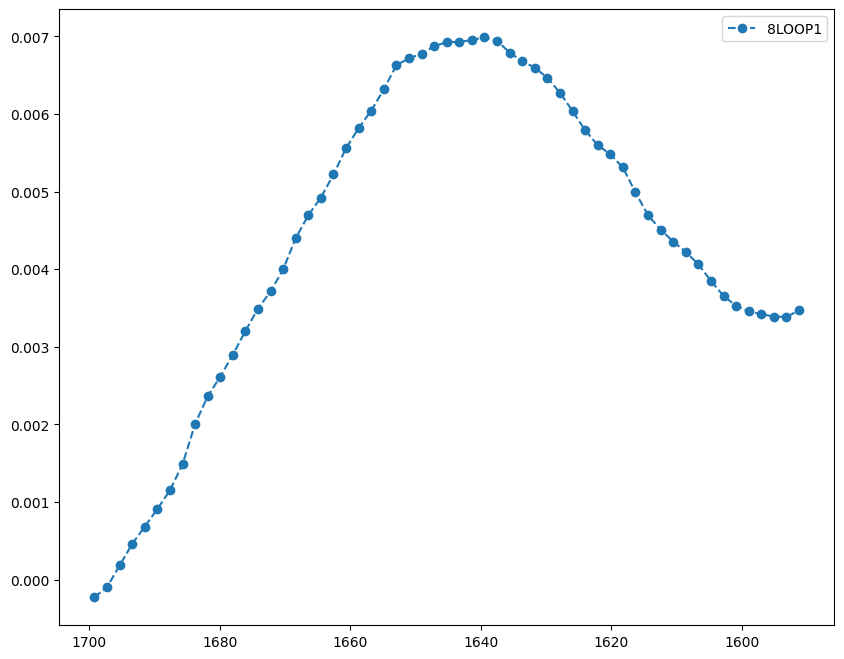

In [7]:
for file in avg_data:
    df = avg_data[file]
    desired_col = []
    for col in df:
        if str(col).startswith("Abs"):
            desired_col.append(col)
    df["Average Abs"] = df[desired_col].mean(axis=1)

fig1 = plt.figure()
ax1 = fig1.add_subplot(1,1,1)

for file in avg_data:
    df = avg_data[file]
    ax1.plot(df["Wavenumber"], df["Average Abs"], "o--", label=file)

ax1.invert_xaxis()
ax1.legend()

fig1.set_figwidth(10)
fig1.set_figheight(8)

### Baselines, smoothing, and second derivative

##### Unless you are incredibly lucky, this Amide I peak will need to be baseline corrected. The below cell will correct the baseline of all absorbance collumns of each sample file using the PyBaselines module. I have elected to use an asymetric least squares algorithm, but the module also has other options to choose from https://pybaselines.readthedocs.io/en/latest/introduction.html

In [8]:
from pybaselines import Baseline

for item in avg_data:
    df = avg_data[item]
    for col in df:
        if str(col).startswith("Abs"):
            x = df["Wavenumber"].values
            y = df[col].values
            baseline_fitter = Baseline(x)
            correct_base, diag = baseline_fitter.asls(y)
            df[col] = y - correct_base
            
        df["Corrected Average Abs"] = df[desired_col].mean(axis=1)
    avg_data[item] = df
    print(avg_data[item])

      Wavenumber     Abs_A     Abs_B     Abs_C     Abs_D  Average Abs  \
1191  1699.20998 -0.000329 -0.000315 -0.000373 -0.000413    -0.000228   
1192  1697.28126 -0.000281 -0.000285 -0.000323 -0.000275    -0.000097   
1193  1695.35253 -0.000093 -0.000096 -0.000134  0.000023     0.000183   
1194  1693.42380  0.000115  0.000114  0.000056  0.000271     0.000460   
1195  1691.49507  0.000273  0.000244  0.000265  0.000408     0.000682   
1196  1689.56634  0.000462  0.000334  0.000525  0.000526     0.000910   
1197  1687.63761  0.000670  0.000464  0.000794  0.000624     0.001150   
1198  1685.70888  0.000958  0.000794  0.001093  0.000791     0.001485   
1199  1683.78015  0.001426  0.001294  0.001563  0.001179     0.002005   
1200  1681.85143  0.001684  0.001534  0.001872  0.001547     0.002363   
1201  1679.92270  0.001832  0.001693  0.002062  0.001805     0.002615   
1202  1677.99397  0.002061  0.001913  0.002281  0.002013     0.002897   
1203  1676.06524  0.002319  0.002143  0.002541  0.0

##### With this corrected data, regraph the average spectra to confirm the baseline is adequate

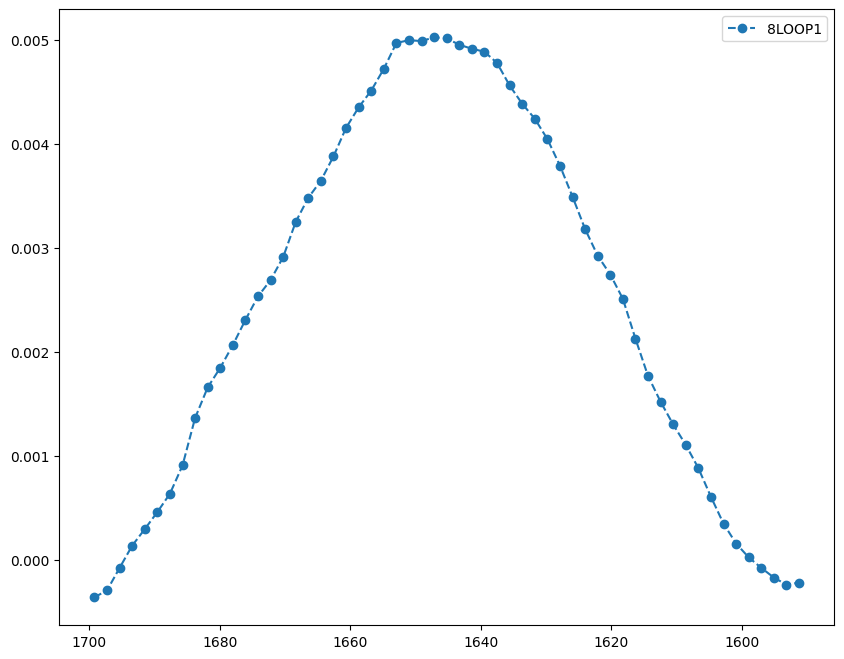

In [9]:
fig2 = plt.figure()
ax2 = fig2.add_subplot(1,1,1)

for file in avg_data:
    df = avg_data[file]
    ax2.plot(df["Wavenumber"], df["Corrected Average Abs"], "o--", label=file)

ax2.invert_xaxis()
ax2.legend()

fig2.set_figwidth(10)
fig2.set_figheight(8)

#### Next step in our method is to smooth the data and calculate the second derivative. Both of these can be achieved with a function from SciPy. The filter used is a Savitsky-Golay filter, a popular choice for spectra smoothing. I have the parameters set to window length = 9 and polyorder = 6 as I have found this to be the best in-between of sharpening existing peaks while not amplifying noise for my data, but yours may differ. Some FTIR is analyzed using higher-order derivatives, but most use second derivative hence why derivative is set to 2.

##### SciPy: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.savgol_filter.html

##### Savitsky-Golay filter background information:
##### https://en.wikipedia.org/wiki/Savitzky%E2%80%93Golay_filter
##### https://medium.com/pythoneers/introduction-to-the-savitzky-golay-filter-a-comprehensive-guide-using-python-b2dd07a8e2ce

In [10]:
from scipy.signal import savgol_filter

for item in avg_data:
    df = avg_data[item]
    for col in df:
        if str(col).startswith("Abs"):
            sav_filt_2 = savgol_filter(df[col], window_length=9, polyorder=6, deriv=2) ###Window length and order can be changed to different values if desired###
            df["Sec Deriv " + col] = sav_filt_2
    avg_data[item] = df

for item in avg_data:
    df = avg_data[item]
    desired_col = []
    new_col = []
    for col in df:
        if str(col).startswith("Sec"):
            desired_col.append(col)
    df["Average Deriv"] = df[desired_col].mean(axis=1)
    avg_data[item] = df

##### The below cell can be used to check what the smoothed second-derivative looks like. To test new polyorders or window lengths, change the prior cell, rerun, then rerun below cell

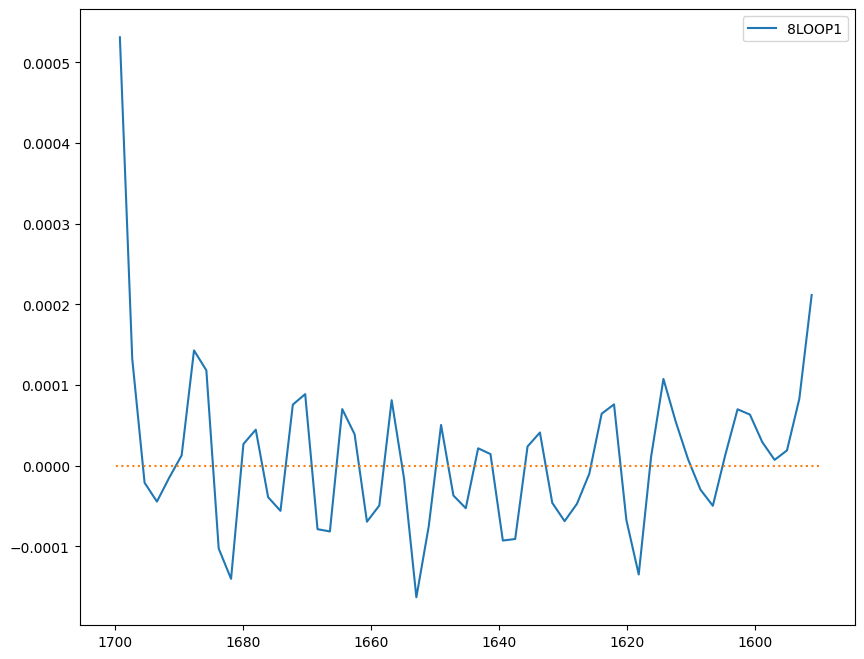

In [11]:
fig3 = plt.figure()
ax3 = fig3.add_subplot(1,1,1)

for file in avg_data:
    df = avg_data[file]
    ax3.plot(df["Wavenumber"], df["Average Deriv"], label=file)

ax3.invert_xaxis()
ax3.legend()

x = [1590, 1700]
y = [0.0, 0.0]
ax3.plot(x, y, linestyle = 'dotted')

fig3.set_figwidth(10)
fig3.set_figheight(8)
# fig3.savefig("Average Second Derivative for Peak Locations.png")

### Peak Fitting

##### The next step requires locating the approximate peak location of each <b>negative peak</b>. I used these papers to identify my peaks.
##### https://www.nature.com/articles/nprot.2015.024
##### https://pubmed.ncbi.nlm.nih.gov/15756815/
##### https://www.sciencedirect.com/science/article/pii/S0268005X17318982
##### https://pmc.ncbi.nlm.nih.gov/articles/PMC7786567/
##### I found it helpful to save the average 2nd derivative graph to mark up as I went along each peak, to do that, remove the hashtag from the prior cell and rerun

##### Once peaks have been identified, in order to do anything meaningful with the data it must be peak fitted with Gaussians and area under the curve (AUC) calculated. This is accomplished first by the following functions which were provided by this YouTube video on Gaussian fitting https://youtu.be/peBOquJ3fDo?si=F1G1vcpBQ-bAD5rw&t=803

##### The first function, gaus_f, defines the Gaussian Fit.
##### The second function, opt_param, takes in a guess of amp (peak height), mu (peak location), and sigma (peak half width, also known as standard deviation) and fits it to a provided dataframe’s (df) data. It then finds optimal fit parameters to the peak data. The “force” parameter, if true, helps correct for flagrantly incorrect optimal mu’s. Whether or not force = True, the bounds will limit guesses to negative amp as this too would result in a fragrantly incorrect parameter.
##### The third function calculates the AUC of given parameters.

In [12]:
from scipy.optimize import curve_fit

def gaus_f(x, amp, mu, sig):
    return amp*np.exp(-(x-mu)**2/sig**2)

def opt_param(params, force=False):
    amp, mu, sigma = params
    if amp > 0:
        amp = 0 - amp
    if force is True:
        lower_bound = [-0.01, mu-0.5, 0.01]
        upper_bound = [0, mu+0.5, 10]
    if force is False:
        lower_bound = [-0.01, 1600, 0.01] ###If working with data in a wavenumber range different from mine (~1700-1600) you will need to change these bounds to mat your data
        upper_bound = [0, 1710, 10]
    popt, pcov = curve_fit(gaus_f, df["Wavenumber"],df["Average Deriv"], p0 = [amp, mu, sigma], bounds = (lower_bound, upper_bound))
    return popt

def AUC(params):
    amp, mu, sigma = params
    auc = abs(amp * sigma * np.sqrt(2 * np.pi))
    return auc

#### These next set of functions allow you to check if the opt_param results in a peak fit you are satisfied with. The IPython.display imports are required to add and remove the lines in a figure of your choosing.

##### The first function, peak_checker, graphs the parameters onto a figure. X_model uses np.linepace to generate its values, y_model uses gaus_f function and x_model to generate its values.

##### The second function, guess_test_input, uses peak_checker and makes it interactive with inputs. This allows you to take an initial guess (usually from a list), check that the fit looks adequate, and return the peak’s dictionary. If it looks inadequate, it can recursively loop through the function until the peak looks adequate based on your guess_input, with the option to change force = True on peak checker. Finally, sometimes the initial guess does not exist in any meaningful way in your data (perhaps due to extreme denaturation). In this case an option to delete the peak and move on to the next guess is required.

In [13]:
from IPython.display import display, clear_output

def peak_checker(params, ax_obj, graph_data):
    cor_amp, cor_mu, cor_sigma = params
    x_model = np.linspace(min(df["Wavenumber"]), max(df["Wavenumber"]), 1000)
    y_model = gaus_f(x_model, cor_amp, cor_mu, cor_sigma)
    [fit_line] = ax_obj.plot(x_model, y_model)
    return fit_line

def guess_test_input(params, ax_obj, fig_obj, test_line=None, force=False):
    peak_dict = {}
    cor_param = opt_param(params,force)
    cor_amp, cor_mu, cor_sigma = cor_param
    peak_loc = int(cor_param[1])
    
    if 1590 < peak_loc < 1710:
        if test_line is not None:
            test_line.remove()
        test_line = peak_checker(cor_param, ax_obj, df)
        clear_output(wait=True)
        display(fig_obj)
        keep_run = input("Does this fit look correct? Y for add peak, NE for no, edit, N for delete ")
        if keep_run.upper() == "Y":
            peak_dict[peak_loc] = cor_param
            return peak_dict
        elif keep_run.upper() == "NE":
            guess_input = input("Enter an alternative guess as amp, mu, sigma (add f if you want to force the mu+/- 0.5) ")
            listed_input = [obj for obj in guess_input.strip().split(",")]
            if len(listed_input) == 3:
                new_params = [float(num) for num in listed_input]
                return guess_test_input(new_params, ax_obj, fig_obj, test_line)
            if len(listed_input) == 4:
                new_params = [float(num) for num in listed_input[:3]]
                return guess_test_input(new_params, ax_obj, fig_obj, test_line, force=True)
        elif keep_run.upper() == "N":
            test_line.remove()
            return None
        else:
            guess_input = input("Enter an alternative guess as amp, mu, sigma (add f if you want to force the mu+/- 0.5) ")
            listed_input = [obj for obj in guess_input.strip().split(",")]
            if len(listed_input) == 3:
                new_params = [float(num) for num in listed_input]
                return guess_test_input(new_params, ax_obj, fig_obj, test_line)
            if len(listed_input) == 4:
                new_params = [float(num) for num in listed_input[:3]]
                return guess_test_input(new_params, ax_obj, fig_obj, test_line, force=True)

##### This cell creates a named tuple to make adding to a guess list easier without worrying about altering the initial guesses so they are consistent between replicates.

In [14]:
from collections import namedtuple
guess = namedtuple("guess", ["amp", "mu", "sigma"])

##### This next cell loops through the avg_data’s sample dictionaries and loops those through a list of guesses where the peak_checker is used. If the peak_checker returns a value it is added to a correct parameter dictionary which is added to a sample dictionary which is added to a main dictionary. (Due to the amount of nested dictionaries I found it easiest to think about this with annotating the lines with dictionaries and what gets added to them).

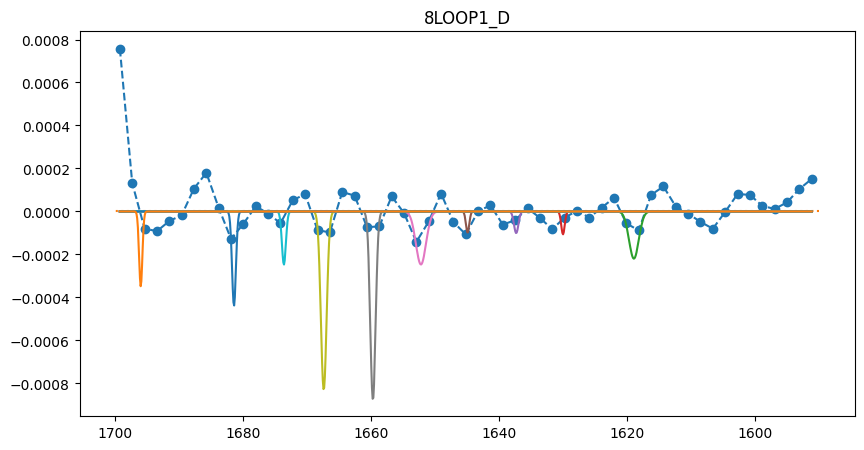

Does this fit look correct? Y for add peak, NE for no, edit, N for delete  y


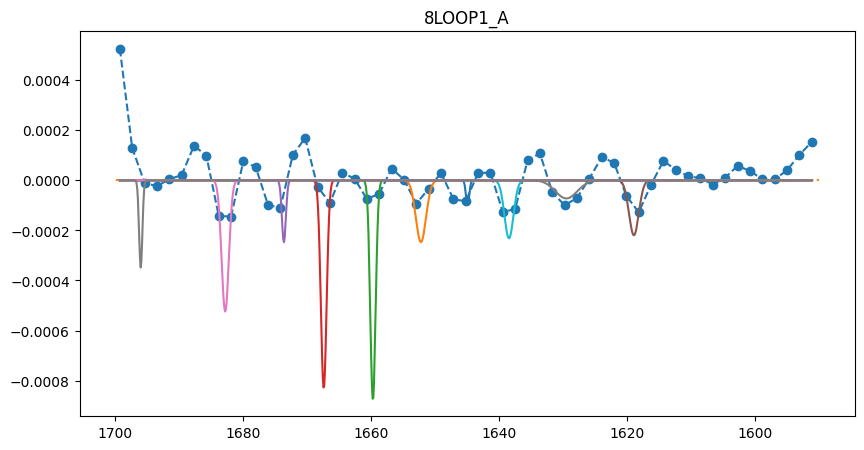

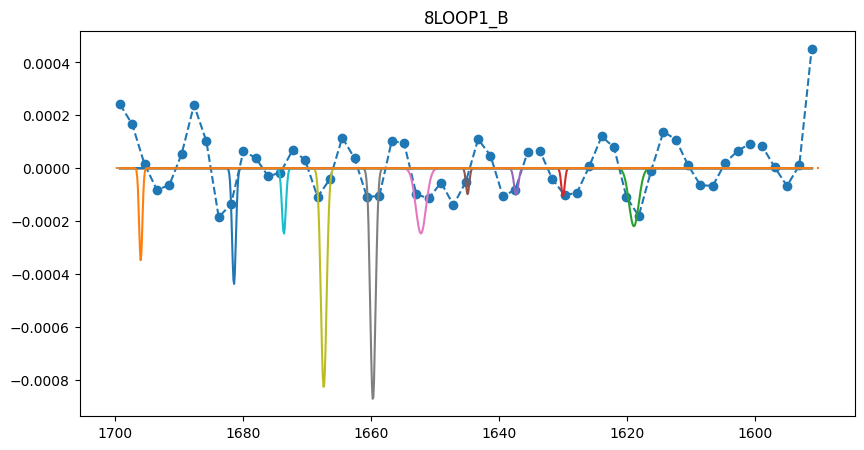

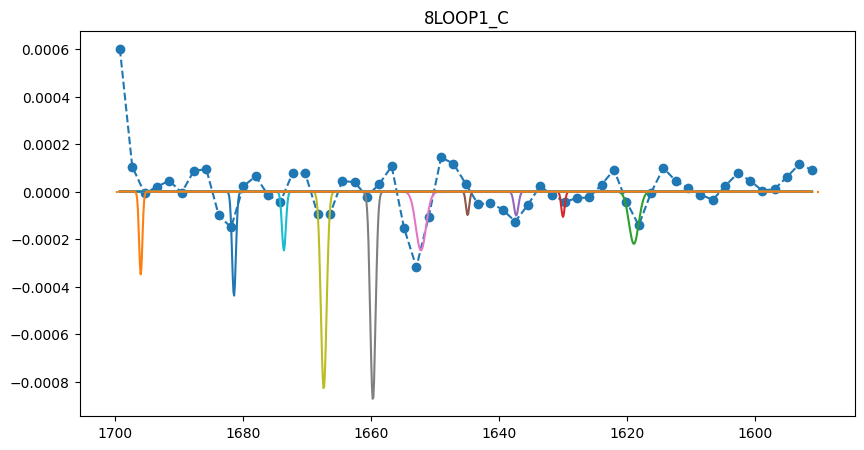

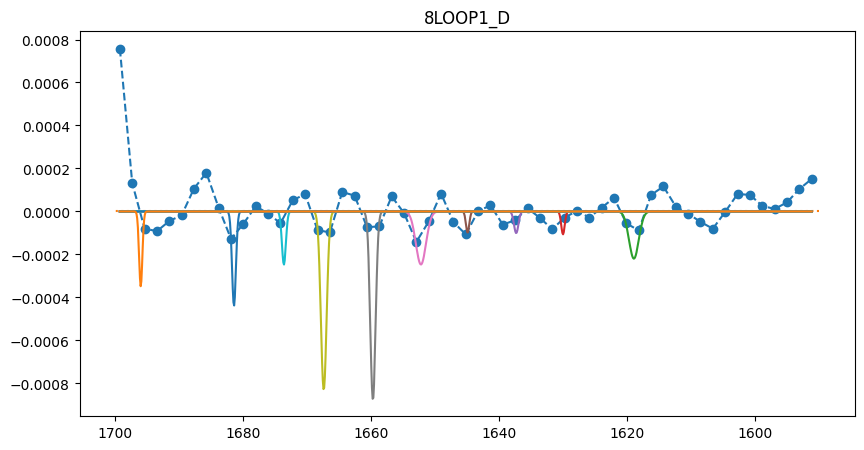

In [15]:
all_dict = {} # Nested dict with each sample as key, then each sample has each deriv as a key, then each deriv has peaks as a key

for file in avg_data:
    df = avg_data[file]
    sample_dict = {} # Nested dic where each col key has a dict of peaks
    for col in df:
        if str(col).startswith("Sec"):
            fig4 = plt.figure()
            ax4 = fig4.add_subplot(1,1,1)
            ax4.plot(df["Wavenumber"], df[col], "o--")
            ax4.invert_xaxis()
            x = [1590, 1700]
            y = [0.0, 0.0]
            ax4.plot(x, y, linestyle = 'dotted')
            title = str(file) + str(col)[-2:]
            ax4.set_title(title)
            fig4.set_figwidth(10)
            fig4.set_figheight(5)
            guess_list = [guess(-0.00024, 1619, 3),
        guess(-0.0002, 1624, 2.5),
        guess(-0.0003, 1636, 0.9),
        guess(-0.00017, 1644, 0.9),
        guess(-0.0009, 1651, 2),
        guess(-0.001, 1659, 1),
        guess(-0.0006, 1667, 0.5),
        guess(-0.0007, 1674, 0.7),
        guess(-0.0008, 1681, 0.8),
        guess(-0.0007, 1696, 0.9)]
            correct_param_dict = {} # Non-nested dict where peak keys reveal correct parameters
            test_line = None
            for obj in guess_list:
                result = guess_test_input(params=obj, ax_obj=ax4, fig_obj=fig4)
                if result is not None:
                    correct_param_dict.update(result) # This puts the peak: param pairs into correct_param_dict
            sample_dict[col] = correct_param_dict
    all_dict[file] = sample_dict

##### All_dict should now be filled with sample dictionaries. You can use the below cell to check the mu’s of all the peaks. This can help you classify the peaks into their respective structure’s in the following cell.

In [16]:
for file in all_dict:
    print(file)
    for item in all_dict[file]:
        print("\t" + item)
        for obj in all_dict[file][item]:
            print("\t" + "\t" + str(obj))
            # for group in all_dict[file][item][obj]:
                # print ("\t" + "\t" + "\t" + str(group))

8LOOP1
	Sec Deriv Abs_A
		1618
		1638
		1644
		1652
		1659
		1667
		1673
		1682
		1695
	Sec Deriv Abs_B
		1618
		1630
		1637
		1644
		1652
		1659
		1667
		1673
		1681
		1695
	Sec Deriv Abs_C
		1618
		1630
		1637
		1644
		1652
		1659
		1667
		1673
		1681
		1695
	Sec Deriv Abs_D
		1618
		1630
		1637
		1644
		1652
		1659
		1667
		1673
		1681
		1695


##### The first cell loops through all_dict and makes a new dictionary (auc_all). The elif statements can be altered if the identified peaks are in different locations than mine, as well as the contribution values (alpha_helix, b_sheet, etc) if different structures are desired.

In [17]:
auc_all = {} ###This is the big dictionary filled with sample types for keys###

for item in all_dict:
    sample_dict = {}
    for sub in all_dict[item]: ###This is the sample type dictinary with replicates as keys###
        sub_dict = {}
        total_auc = 0
        a_helix = 0
        three_helix = 0
        random = 0
        b_turn = 0
        b_sheet = 0
        for entry in all_dict[item][sub]: ###This entry is the wavenuber code to access the amp, mu, sigma data needed to get the AUC of the peak###
            calcs = all_dict[item][sub][entry]
            peak = calcs[1]
            if 1648 < peak <= 1654:
                a_helix += AUC(calcs)
            elif 1656 <= peak <= 1664:
                three_helix += AUC(calcs)
            elif 1639 <= peak <= 1648:
                random += AUC(calcs)
            elif 1665 <= peak <= 1685:
                b_turn += AUC(calcs)
            else:
                b_sheet += AUC(calcs)
        total_auc = a_helix + three_helix + b_turn + b_sheet + random ###Total curve area, can calc relative contributions with this###
        sub_dict["a_helix"] = (a_helix/total_auc)*100
        sub_dict["three_helix"] = (three_helix/total_auc)*100
        sub_dict["random"] = (random/total_auc)*100
        sub_dict["b_turn"] = (b_turn/total_auc)*100
        sub_dict["b_sheet"] = (b_sheet/total_auc)*100
        name = str(item) + " " + str(sub)[-1]
        sample_dict[name] = sub_dict
    auc_all[item] = sample_dict
auc_all

{'8LOOP1': {'8LOOP1 A': {'a_helix': np.float64(11.200489419271854),
   'three_helix': np.float64(20.84120084386906),
   'random': np.float64(1.4600541504789446),
   'b_turn': np.float64(42.49923191311784),
   'b_sheet': np.float64(23.99902367326229)},
  '8LOOP1 B': {'a_helix': np.float64(13.180796791857244),
   'three_helix': np.float64(24.526038366560986),
   'random': np.float64(1.7181996555844996),
   'b_turn': np.float64(39.08505895153756),
   'b_sheet': np.float64(21.489906234459696)},
  '8LOOP1 C': {'a_helix': np.float64(13.180796791857244),
   'three_helix': np.float64(24.526038366560986),
   'random': np.float64(1.7181996555844996),
   'b_turn': np.float64(39.08505895153756),
   'b_sheet': np.float64(21.489906234459696)},
  '8LOOP1 D': {'a_helix': np.float64(13.180796791857244),
   'three_helix': np.float64(24.526038366560986),
   'random': np.float64(1.7181996555844996),
   'b_turn': np.float64(39.08505895153756),
   'b_sheet': np.float64(21.489906234459696)}}}

##### This next loop makes a flattened csv that can be exported. All identifying information is retained and can be used in excel, Prism, JMP, etc.

In [18]:
csv_rows = []

for sample_id, replicate in auc_all.items():
    for replicate_dict, peak_dict in replicate.items():
        for structure, contribution in peak_dict.items():
            csv_rows.append({
            "Sample": sample_id,
            "Replicate": replicate_dict,
            "Structure": structure,
            "Percent Contribution": contribution})

final_data = pd.DataFrame(csv_rows)
final_data.to_csv("Batch FTIR Redo.csv", index=False)
# final_data

### Concluding thoughts

##### The purpose of this project was to make a program that could utilize the .dpt files my janky FTIR spectrometer could produce (courtesy of the chem building). I also needed it to be interactive to a certain extent as uploading data and accepting the results a program spits out, with no way to verify its validity yourself, is in my opinion, poor science. Finally, I wanted it user friendly enough that it could be implemented as a lab (or even department) resource. This includes helpful documentation of the theory behind how FTIR can be utilized, the steps required to deconvolute, and the option to change the code for someone who has limited experience in programming.

##### While I do see improvements that could be made (in particular making the guess list a mutable input/output list, as well as giving the program the ability to reassign the guess values with accepted values, thus removing the wrong guess trap across replicates) I believe the said goals have been accomplished. 

##### The other major improvement I could see implementing is a section that can run my stats and build my table and graph that I normally make with Prism, BioRender, and Word.

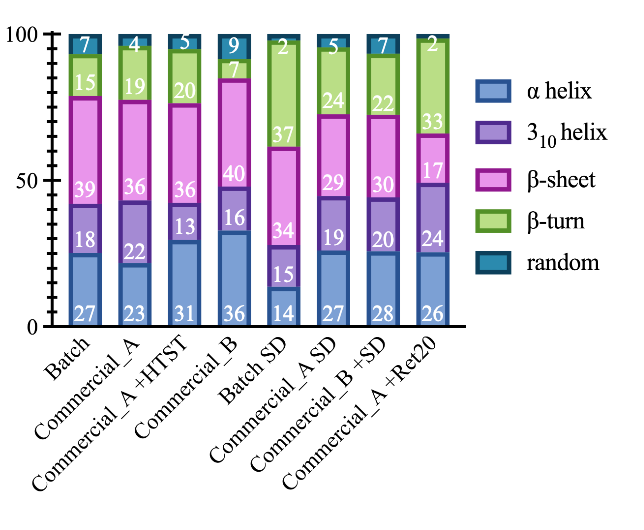 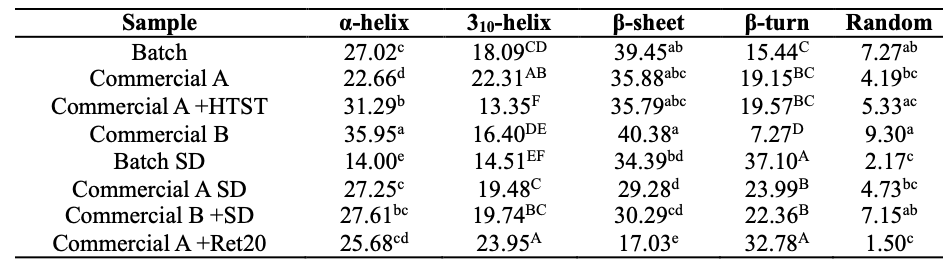

##### However, this would 1) ultimately make this project take another drastic turn of learning how to run true stats in python, something I really do not want to do and 2) strongly suggest to future user that such statistics and graphs are the ideal form for this data analysis and presentation. That again would be counter intuitive to my goal of this being a flexible resource for other lab members to use in the future.